<a href="https://colab.research.google.com/github/hafizatunabila/Project-1-Computer-Vision-and-Deep-Learning/blob/main/Project1_503_4222401012_Hafiza.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project 1 - Deteksi Mobil dan Motor (YOLO26n)


## 1. Persiapan

In [6]:
!pip install -q ultralytics
import glob, torch
from pathlib import Path

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)
if device == "cpu":
    print("GPU belum aktif -> pelatihan akan lambat. Aktifkan T4 GPU lalu jalankan ulang.")

Device: cuda


## 2. Ambil dataset dari GitHub

In [7]:
GITHUB_USER = "hafizatunabila"
GITHUB_REPO = "Project-1-Computer-Vision-and-Deep-Learning"

!rm -rf repo
!git clone -q https://github.com/{GITHUB_USER}/{GITHUB_REPO}.git repo

## 3. Cek dataset dan program


In [8]:
yaml_hit = glob.glob("repo/**/dataset_v1/data.yaml", recursive=True)
skrip_hit = glob.glob("repo/**/03_latih_bandingkan.py", recursive=True)
assert yaml_hit, "dataset_v1/data.yaml tidak ada di repo. Pastikan sudah di-push."
assert skrip_hit, "03_latih_bandingkan.py tidak ada di repo. Pastikan sudah di-push."

DATA = Path(yaml_hit[0])
SKRIP = skrip_hit[0]
baris = [b for b in DATA.read_text().splitlines() if not b.startswith("path:")]
DATA.write_text(f"path: {DATA.parent.resolve().as_posix()}\n" + "\n".join(baris) + "\n")

for s in ("train", "val", "test"):
    print(f"{s:5s}: {len(list((DATA.parent / 'images' / s).glob('*')))} gambar")
print(DATA.read_text())

train: 72 gambar
val  : 20 gambar
test : 11 gambar
path: /content/repo/dataset_v1
train: images/train
val: images/val
test: images/test
names:
  0: car
  1: motorcycle



## 4. Latih E1, E2, E3


In [9]:
NIM = "4222401012"
NAMA = "Nur Hafidzatun Nabila"

!python {SKRIP} --nim {NIM} --nama "{NAMA}" --data {DATA}

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.

=== E1_pretrained: yolo26n.pt | pretrained=True | pengaturan dasar ===
Ultralytics 8.4.179 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=repo/dataset_v1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_

## 5. Lihat hasil

  PROJECT-1 503 COMPUTER VISION DAN DEEP LEARNING
  NIM / Nama    : 4222401012 / Nur Hafidzatun Nabila
  Waktu         : 17-10-2026 12:40:34
  Komputer/user : 020b23906406 / root
  Dataset       : repo/dataset_v1  (sidik jari label: B423D13CAF1C)
  Pengaturan    : model yolo26n, epochs 30, imgsz 416, batch 16
  Eksperimen     Perubahan        mAP50  mAP50-95      P      R     ms   menit
  E1_pretrained  -                0.995     0.979  0.990  1.000    8.4     1.4
  E2_scratch     -                0.125     0.038  0.237  0.135    5.5     1.0
  E3_tuning      imgsz=640        0.995     0.985  0.988  1.000   12.0     1.3
  Model terpilih (mAP50-95 val tertinggi): E3_tuning
  Hasil di data TEST (sekali saja)       : mAP50 0.945 | mAP50-95 0.911



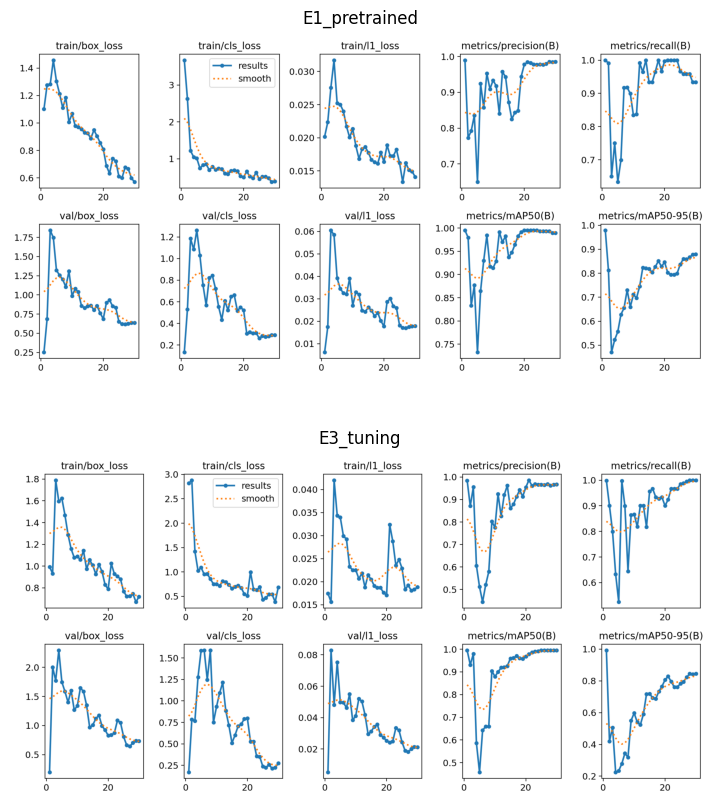

In [10]:
import matplotlib.pyplot as plt, matplotlib.image as mpimg

print(open(f"hasil_praktik_{NIM}.txt", encoding="utf-8").read())
fig, ax = plt.subplots(2, 1, figsize=(12, 10))
for a, e in zip(ax, ["E1_pretrained", "E3_tuning"]):
    a.imshow(mpimg.imread(f"hasil_praktik/{e}/results.png")); a.set_title(e); a.axis("off")
plt.show()

## 6. Unduh hasil


In [11]:
!zip -qr hasil_colab.zip hasil_praktik hasil_praktik_{NIM}.txt hasil_praktik_{NIM}.csv -x '*.pt'
from google.colab import files
files.download("hasil_colab.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>